In [4]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [5]:
# Load the insurance dataset from the given CSV file path
df=pd.read_csv(r"C:\Users\ATUL\Downloads\Insurance Premium.csv")

In [6]:
#Display the first 5 rows of the dataset to understand its structure
df.head()

,ID,Age,Gender,BMI,Children,Smoker,Region,Premium
0,1,19,female,27.900,0,yes,south,16885
1,2,18,male,33.770,1,no,east,1726
2,3,28,male,33.000,3,no,east,4449
3,4,33,male,22.705,0,no,west,21984
4,5,32,male,28.880,0,no,west,3867


In [7]:
# Check the total number of rows and columns in the dataset
df.shape

(1338, 8)

In [8]:
# Check for missing (null) values in each column
df.isnull().sum()

ID          0
Age         0
Gender      0
BMI         0
Children    0
Smoker      0
Region      0
Premium     0
dtype: int64

In [9]:
# Get detailed information about the dataset (column names, data types, non-null counts)
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 1338 entries, 0 to 1337
Data columns (total 8 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   ID        1338 non-null   int64  
 1   Age       1338 non-null   int64  
 2   Gender    1338 non-null   str    
 3   BMI       1338 non-null   float64
 4   Children  1338 non-null   int64  
 5   Smoker    1338 non-null   str    
 6   Region    1338 non-null   str    
 7   Premium   1338 non-null   int64  
dtypes: float64(1), int64(4), str(3)
memory usage: 99.0 KB


In [10]:
# Select only the columns that have string (object/categorical) data type
strcols=df.select_dtypes(include='str')
strcols

,Gender,Smoker,Region
0,female,yes,south
1,male,no,east
2,male,no,east
3,male,no,west
4,male,no,west
...,...,...,...
1333,male,no,west
1334,female,no,north
1335,female,no,east
1336,female,no,south


In [11]:
# Loop through each categorical column and print the count of unique values
for i in strcols:
    print(f"We are checking {i} column =====")
    print(df[i].value_counts())

We are checking Gender column =====
Gender
male      676
female    662
Name: count, dtype: int64
We are checking Smoker column =====
Smoker
no     1064
yes     274
Name: count, dtype: int64
We are checking Region column =====
Region
east     364
south    325
west     325
north    324
Name: count, dtype: int64


In [12]:
#Generate basic statistical summary (mean, std, min, max, etc.) for numerical columns
df.describe()

,ID,Age,BMI,Children,Premium
count,1338.000000,1338.000000,1338.000000,1338.000000,1338.000000
mean,669.500000,39.207025,30.663397,1.094918,13270.414798
std,386.391641,14.049960,6.098187,1.205493,12110.012882
min,1.000000,18.000000,15.960000,0.000000,1122.000000
25%,335.250000,27.000000,26.296250,0.000000,4740.000000
50%,669.500000,39.000000,30.400000,1.000000,9382.000000
75%,1003.750000,51.000000,34.693750,2.000000,16640.000000
max,1338.000000,64.000000,53.130000,5.000000,63770.000000


In [13]:
# Generate statistical summary specifically for categorical (string) columns
strcols.describe()

,Gender,Smoker,Region
count,1338,1338,1338
unique,2,2,4
top,male,no,east
freq,676,1064,364


In [14]:
#  Drop unnecessary column/ Drop the 'ID' column as it is not useful for analysis
df = df.drop(columns=['ID'])

In [15]:
#  Basic Statistical Summary
print(df.describe())

               Age          BMI     Children       Premium
count  1338.000000  1338.000000  1338.000000   1338.000000
mean     39.207025    30.663397     1.094918  13270.414798
std      14.049960     6.098187     1.205493  12110.012882
min      18.000000    15.960000     0.000000   1122.000000
25%      27.000000    26.296250     0.000000   4740.000000
50%      39.000000    30.400000     1.000000   9382.000000
75%      51.000000    34.693750     2.000000  16640.000000
max      64.000000    53.130000     5.000000  63770.000000


In [16]:
# Show statistical summary of categorical columns after dropping ID
df.describe(include='str')

,Gender,Smoker,Region
count,1338,1338,1338
unique,2,2,4
top,male,no,east
freq,676,1064,364


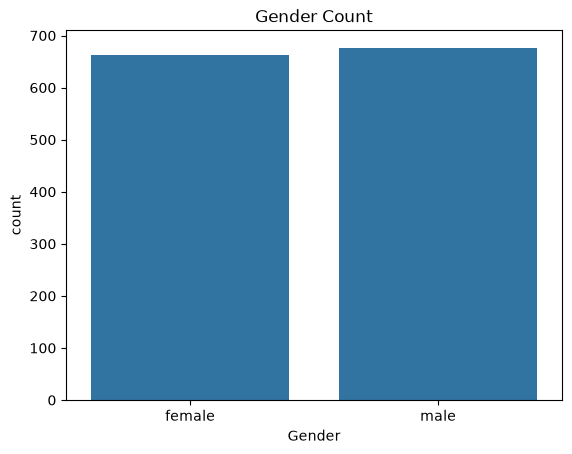

In [17]:
#  Visualization

# Create a Count Plot for Gender
# This bar chart shows how many Male and Female customers are in the dataset
# From the visual we can see that Male and Female counts are almost equal
sns.countplot(x='Gender', data=df)
plt.title("Gender Count")
plt.show()

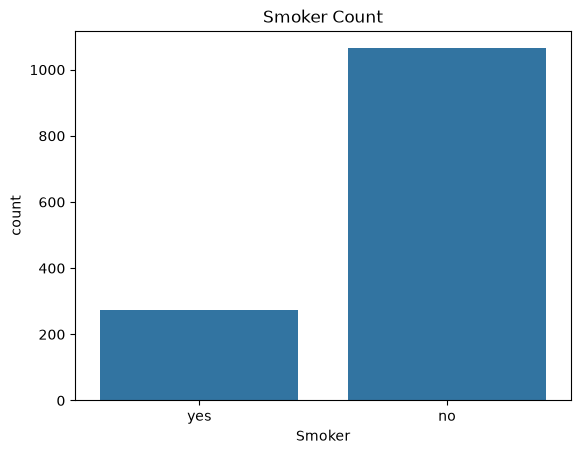

In [18]:
# Smoker count
sns.countplot(x='Smoker', data=df)
plt.title("Smoker Count")
plt.show()

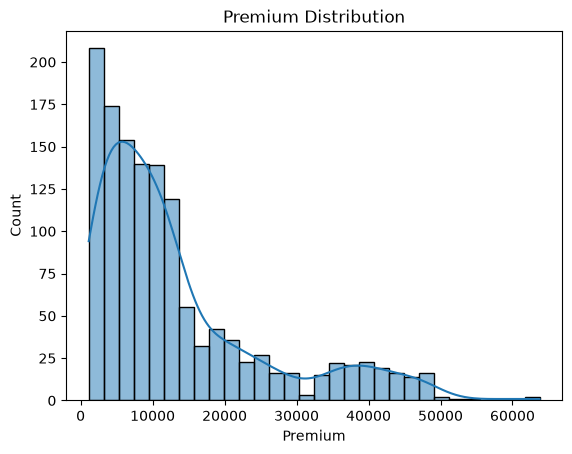

In [19]:
# Premium distribution
sns.histplot(df['Premium'], kde=True)
plt.title("Premium Distribution")
plt.show()

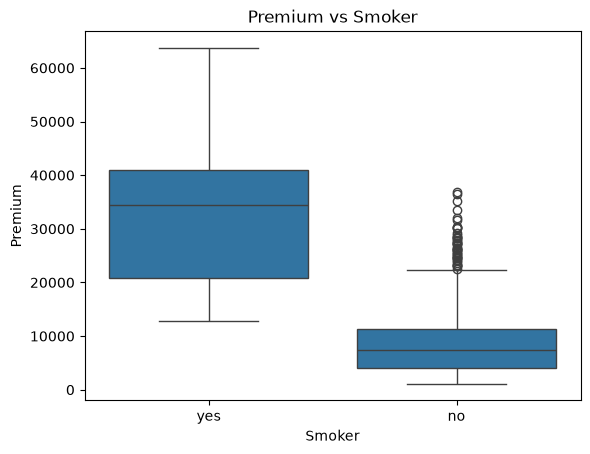

In [20]:
# Premium vs Smoker
sns.boxplot(x='Smoker', y='Premium', data=df)
plt.title("Premium vs Smoker")
plt.show()

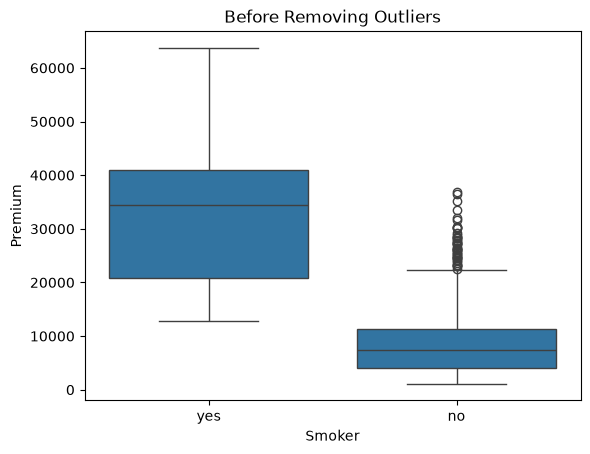

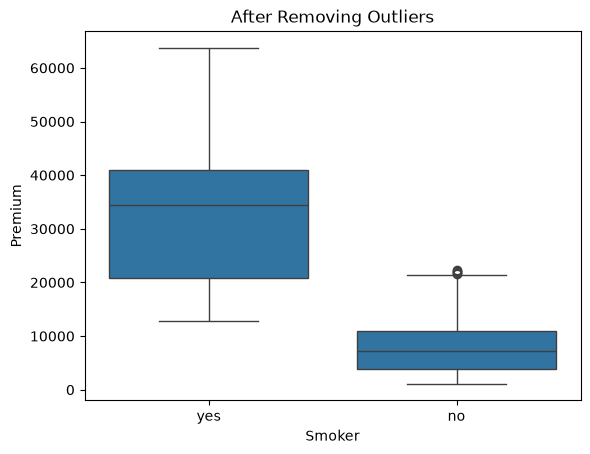

Original rows: 1338
Cleaned rows: 1292
Outliers removed: 46


In [50]:

import matplotlib.pyplot as plt
import seaborn as sns

# Step 1: Boxplot before removing outliers
sns.boxplot(x='Smoker', y='Premium', data=df)
plt.title("Before Removing Outliers")
plt.show()

# Step 2: Remove outliers separately for each smoker group
cleaned_data = []

for smoker in df['Smoker'].unique():
    group = df[df['Smoker'] == smoker]

    Q1 = group['Premium'].quantile(0.25)
    Q3 = group['Premium'].quantile(0.75)
    IQR = Q3 - Q1

    lower = Q1 - 1.5 * IQR
    upper = Q3 + 1.5 * IQR

    group = group[
        (group['Premium'] >= lower) &
        (group['Premium'] <= upper)
    ]

    cleaned_data.append(group)

# Step 3: Combine cleaned data
df_cleaned = pd.concat(cleaned_data)

# Step 4: Boxplot after removing outliers
sns.boxplot(x='Smoker', y='Premium', data=df_cleaned)
plt.title("After Removing Outliers")
plt.show()

# Step 5: Check how many rows were removed
print("Original rows:", len(df))
print("Cleaned rows:", len(df_cleaned))
print("Outliers removed:", len(df) - len(df_cleaned))



In [51]:

# Check outliers remaining in cleaned data

for smoker in df_cleaned['Smoker'].unique():
    group = df_cleaned[df_cleaned['Smoker'] == smoker]

    Q1 = group['Premium'].quantile(0.25)
    Q3 = group['Premium'].quantile(0.75)
    IQR = Q3 - Q1

    lower = Q1 - 1.5 * IQR
    upper = Q3 + 1.5 * IQR

    outliers = group[
        (group['Premium'] < lower) |
        (group['Premium'] > upper)
    ]

    print(smoker, "Remaining outliers:", len(outliers))


yes Remaining outliers: 0
no Remaining outliers: 5


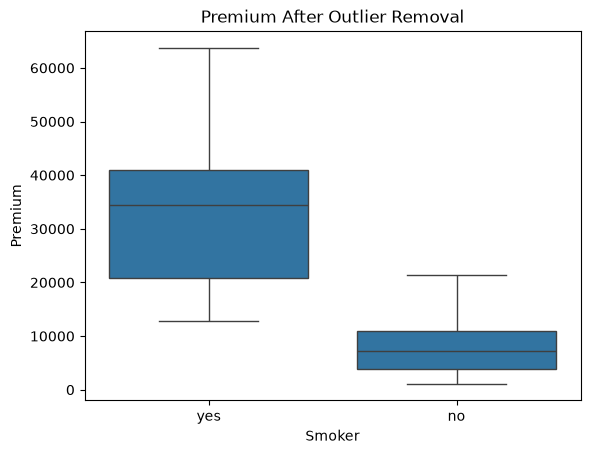

In [52]:
sns.boxplot(
    x='Smoker',
    y='Premium',
    data=df_cleaned,
    showfliers=False
)

plt.title("Premium After Outlier Removal")
plt.show()

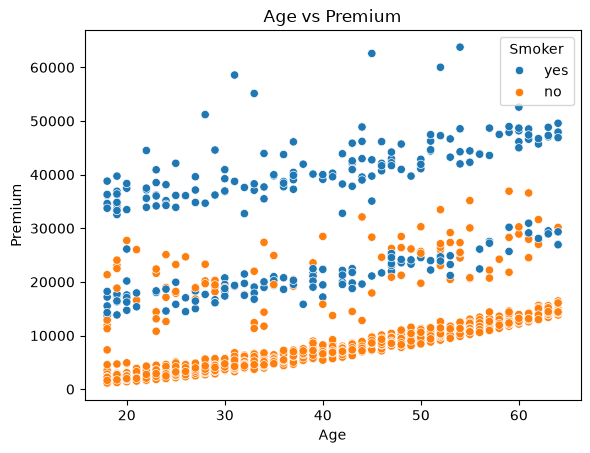

In [40]:
# Scatter Plot: Age vs Premium
# This plot shows the relationship between Age and Insurance Premium
# We can observe that as Age increases, Premium generally increases
sns.scatterplot(x='Age', y='Premium', hue='Smoker', data=df)
plt.title("Age vs Premium")
plt.show()

Distribution of Premium for Gender


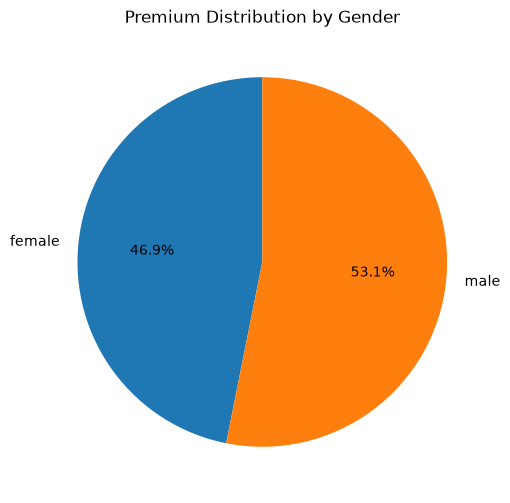

Distribution of Premium for Smoker


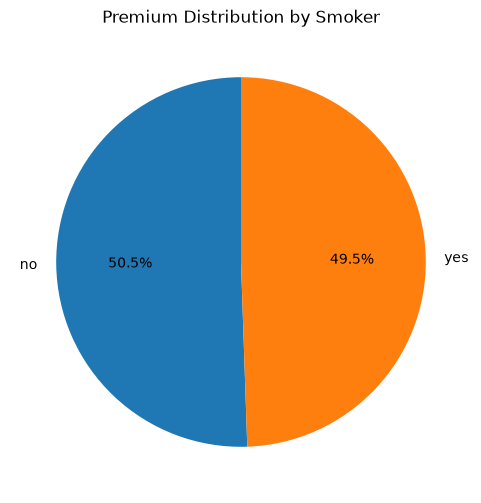

Distribution of Premium for Region


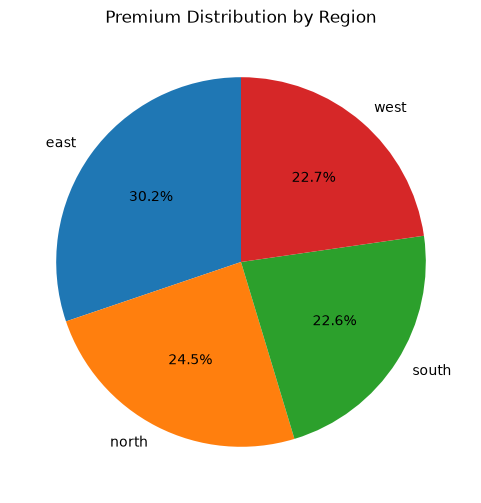

In [41]:
# Create Pie Charts for Premium Distribution
# This loop creates 3 pie charts (one for Gender, one for Smoker, one for Region)
# Each pie chart shows what percentage of TOTAL PREMIUM comes from each category
for i in strcols:
    print(f"Distribution of Premium for {i}")
    grp = df.groupby(i)['Premium'].sum()
    plt.figure(figsize=(6,6))
    plt.pie(grp, labels=grp.index, autopct='%1.1f%%', startangle=90)
    plt.title(f"Premium Distribution by {i}")
    plt.show()

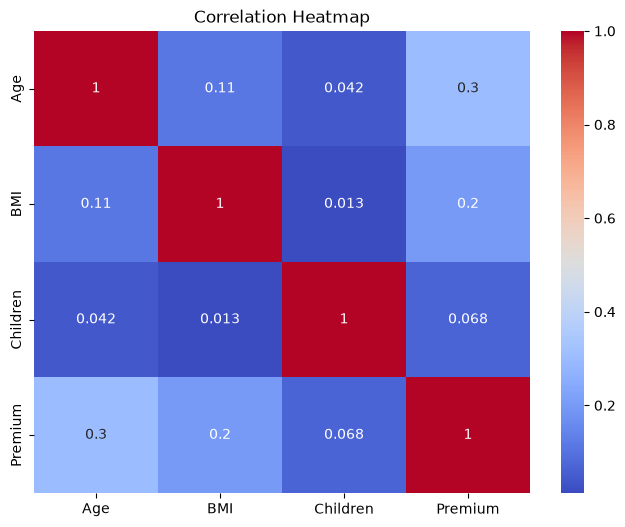

In [42]:

# Create Correlation Heatmap
# This heatmap shows the relationship between numerical columns (Age, BMI, Children, Premium)
# Darker red = strong positive correlation
# Darker blue = strong negative correlation
# Values close to 0 mean almost no relationship
Correlation Heatmap
plt.figure(figsize=(8,6))
sns.heatmap(df.corr(numeric_only=True), annot=True, cmap='coolwarm')
plt.title("Correlation Heatmap")
plt.show()